In [1]:
# use the plain inline backend so the notebook works in every front end without
# any extra package, widget or VS Code setting
%matplotlib inline

In [2]:
# 02: importing the necessary dependencies
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

In [3]:
# 03: loading the world_cities_pop dataset and looking at the first five rows
dataset = pd.read_csv('world_cities_pop.csv', low_memory=False)
dataset.head()

,Country,City,AccentCity,Region,Population,Latitude,Longitude
0,ad,aixas,Aixàs,06,NaN,42.483333,1.466667
1,ad,aixirivali,Aixirivali,06,NaN,42.466667,1.500000
2,ad,aixirivall,Aixirivall,06,NaN,42.466667,1.500000
3,ad,aixirvall,Aixirvall,06,NaN,42.466667,1.500000
4,ad,aixovall,Aixovall,06,NaN,42.466667,1.483333


In [4]:
# 04: mapping the Latitude and Longitude columns to lat and lon
dataset = dataset.rename(columns={'Latitude': 'lat', 'Longitude': 'lon'})
dataset.head()

,Country,City,AccentCity,Region,Population,lat,lon
0,ad,aixas,Aixàs,06,NaN,42.483333,1.466667
1,ad,aixirivali,Aixirivali,06,NaN,42.466667,1.500000
2,ad,aixirivall,Aixirivall,06,NaN,42.466667,1.500000
3,ad,aixirvall,Aixirvall,06,NaN,42.466667,1.500000
4,ad,aixovall,Aixovall,06,NaN,42.466667,1.483333


In [5]:
# 05: filtering the dataset to only contain European cities
europe_country_codes = [
    'al', 'ad', 'at', 'by', 'be', 'ba', 'bg', 'hr', 'cy', 'cz',
    'dk', 'ee', 'fo', 'fi', 'fr', 'de', 'gi', 'gr', 'gg', 'va',
    'hu', 'is', 'ie', 'im', 'it', 'je', 'lv', 'li', 'lt', 'lu',
    'mk', 'mt', 'md', 'mc', 'me', 'nl', 'no', 'pl', 'pt', 'ro',
    'ru', 'sm', 'rs', 'sk', 'si', 'es', 'se', 'ch', 'ua', 'gb'
]
europe = dataset[dataset['Country'].isin(europe_country_codes)]

In [6]:
# 06: comparing the length of all data with the filtered data of Europe
print('Number of cities in the whole dataset:', len(dataset))
print('Number of cities in Europe:', len(europe))

Number of cities in the whole dataset: 3173958
Number of cities in Europe: 898604


In [7]:
# 07: filtering down the European dataset to cities starting with the letter Z
europe_z = europe[europe['City'].str.upper().str.startswith('Z')]

In [8]:
# 08: printing the length and the first five rows of the filtered dataset
print('Number of European cities starting with Z:', len(europe_z))
europe_z.head()

Number of European cities starting with Z: 20738


,Country,City,AccentCity,Region,Population,lat,lon
104206,al,zaane,ZÄane,44,NaN,40.932778,19.783056
104207,al,zabarzani,Zabarzani,40,NaN,40.427778,20.269167
104208,al,zabarzan,Zabarzan,40,NaN,40.427778,20.269167
104209,al,zaberzane,Zabërzanë,40,NaN,40.427778,20.269167
104210,al,zaberzan i siperm,Zaberzan i Sipërm,40,NaN,40.427778,20.269167


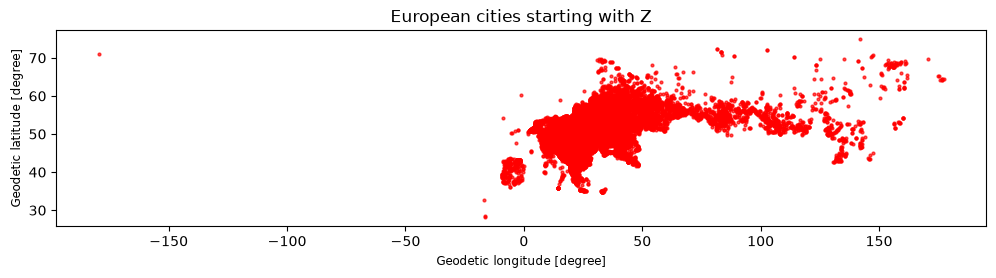

In [9]:
# 09: dot density plot with a tooltip that shows the country code and the city name.
# The geoplotlib DataAccessObject / f_tooltip is replaced by a matplotlib
# mouse motion event that shows an annotation.
z_gdf = gpd.GeoDataFrame(
    europe_z,
    geometry=[Point(xy) for xy in zip(europe_z['lon'], europe_z['lat'])],
    crs='EPSG:4326'
)

fig, ax = plt.subplots(figsize=(12, 8))
z_gdf.plot(ax=ax, color='red', markersize=4, alpha=0.7)
ax.set_title('European cities starting with Z')

annot = ax.annotate('', xy=(0, 0), xytext=(12, 12), textcoords='offset points',
                    bbox=dict(boxstyle='round', fc='yellow', alpha=0.9),
                    arrowprops=dict(arrowstyle='->'))
annot.set_visible(False)


def on_move(event):
    if event.inaxes != ax:
        return
    dist = (z_gdf.geometry.x - event.xdata) ** 2 + \
           (z_gdf.geometry.y - event.ydata) ** 2
    idx = dist.idxmin()
    if dist.loc[idx] < 0.25:      # only show the tooltip when close to a city
        row = z_gdf.loc[idx]
        annot.xy = (row.geometry.x, row.geometry.y)
        annot.set_text('{} - {}'.format(row['Country'], row['City']))
        annot.set_visible(True)
    elif annot.get_visible():
        annot.set_visible(False)
    fig.canvas.draw_idle()


fig.canvas.mpl_connect('motion_notify_event', on_move)
plt.show()

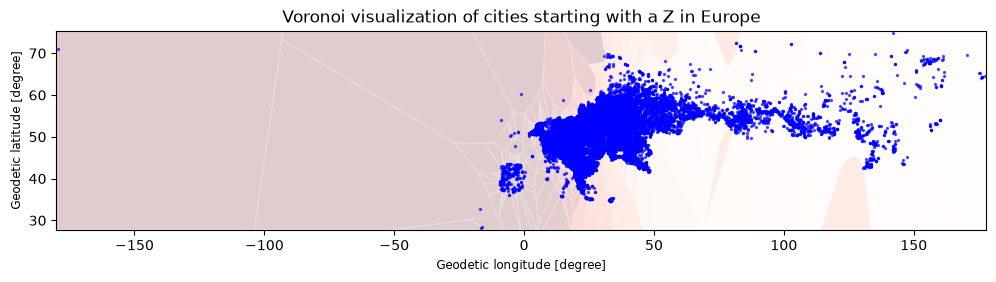

In [10]:
# 10: Voronoi plot of the same dataset (cities starting with Z),
# using the 'Reds_r' color map and an alpha of 0.2 (50 / 255).
# geoplotlib.voronoi is replaced by shapely's voronoi_diagram + a GeoDataFrame.
from shapely.ops import voronoi_diagram
from shapely.geometry import MultiPoint, box

points = MultiPoint(z_gdf.geometry.tolist())
minx, miny, maxx, maxy = z_gdf.total_bounds
envelope = box(minx - 0.5, miny - 0.5, maxx + 0.5, maxy + 0.5)

# voronoi_diagram only extends the unbounded cells to the envelope, it does not
# clip them, so the cells are intersected with the envelope explicitly
regions = voronoi_diagram(points, envelope=envelope)
cells = [region.intersection(envelope) for region in regions.geoms]
cells = [cell for cell in cells if not cell.is_empty]

voronoi_gdf = gpd.GeoDataFrame(geometry=cells, crs='EPSG:4326')
# give every cell a value so that the color map is actually applied
voronoi_gdf['cell'] = range(len(voronoi_gdf))

fig, ax = plt.subplots(figsize=(12, 8))
voronoi_gdf.plot(ax=ax, column='cell', cmap='Reds_r', alpha=0.2,
                 edgecolor='white')
z_gdf.plot(ax=ax, color='blue', markersize=2, alpha=0.6)
ax.set_xlim(envelope.bounds[0], envelope.bounds[2])
ax.set_ylim(envelope.bounds[1], envelope.bounds[3])
ax.set_title('Voronoi visualization of cities starting with a Z in Europe')
plt.show()

In [11]:
# 11-15: interactive custom layer that plots all the European cities starting
# with the provided letter. The geoplotlib BaseLayer + BatchPainter + pyglet key
# handling is replaced by a matplotlib figure, a scatter artist and key events.
import string

start_letters = list(string.ascii_uppercase)
europe_bbox = {'north': 72, 'west': -12, 'south': 34, 'east': 45}


class FilterLayer:
    def __init__(self, data, bbox=europe_bbox):
        self.data = data
        self.view = bbox
        self.start_letter = 0
        self.fig, self.ax = plt.subplots(figsize=(12, 8))
        self.invalidate()
        self.draw()
        self.fig.canvas.mpl_connect('key_press_event', self.on_key_release)

    # 11: filter self.data in the invalidate method using the current letter
    def invalidate(self):
        letter = start_letters[self.start_letter]
        self.filtered = self.data[self.data['City'].str.upper() \
                                  .str.startswith(letter)]

    # 12 + 13: project the lon and lat values to x and y, paint the points with a
    # size of 2 and show which starting letter is currently used
    def draw(self):
        self.ax.clear()
        self.ax.scatter(self.filtered['lon'], self.filtered['lat'],
                        s=2, color='red')
        self.ax.set_xlim(self.view['west'], self.view['east'])
        self.ax.set_ylim(self.view['south'], self.view['north'])
        self.ax.set_aspect('equal')
        self.ax.set_title(
            'Cities in Europe starting with "{}" - use the left/right arrow '
            'keys to switch'.format(start_letters[self.start_letter]))
        self.fig.canvas.draw_idle()

    # 14: check which key is pressed. pyglet.window.key.RIGHT / LEFT is replaced
    # by the matplotlib 'right' / 'left' key events. Use modulo to allow rotation.
    def on_key_release(self, event):
        changed = False
        if event.key == 'right':
            self.start_letter = (self.start_letter + 1) % len(start_letters)
            changed = True
        elif event.key == 'left':
            self.start_letter = (self.start_letter - 1) % len(start_letters)
            changed = True
        if changed:
            self.invalidate()
            self.draw()
            return True
        return False

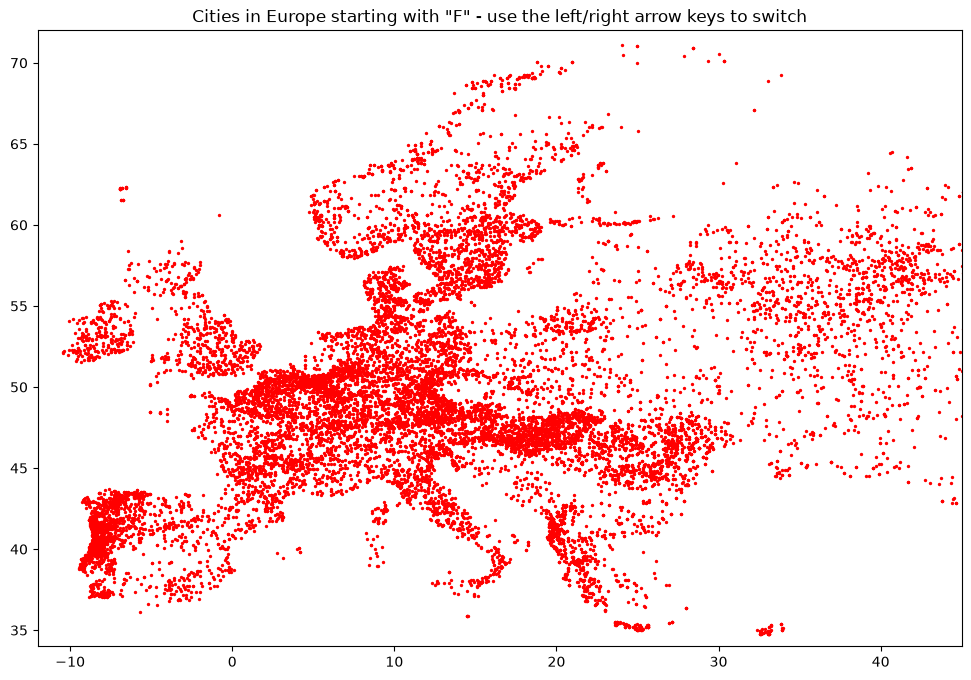

The image above shows the cities starting with "F".
For real key control, re-run with an interactive backend (for example the
magic %matplotlib tk, which opens a native window) and press left/right.


In [12]:
# 15: adding the custom layer using the given europe_bbox.
# The inline backend cannot capture key presses, so the letters are stepped through
# here to show the same effect; every frame is a normal PNG image.
from IPython.display import display, clear_output

filter_layer = FilterLayer(europe)

for letter_index in range(6):          # A, B, C, D, E, F
    filter_layer.start_letter = letter_index
    filter_layer.invalidate()
    filter_layer.draw()
    clear_output(wait=True)
    display(filter_layer.fig)

# close the figure so the inline backend does not show it a second time
plt.close(filter_layer.fig)

print('The image above shows the cities starting with "F".')
print('For real key control, re-run with an interactive backend (for example the')
print('magic %matplotlib tk, which opens a native window) and press left/right.')

In [13]:
# 16: save this notebook as "Mc663385_Activity8.02.ipynb"